In [83]:
#Data Preparation and Exploration
#Data Loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
# Load the dataset and parse dates
df = pd.read_csv('exchange_rate[1].csv', parse_dates=['date'], index_col='date')
print(df.head())


            Ex_rate
date               
1990-01-01   0.7855
1990-02-01   0.7818
1990-03-01   0.7867
1990-04-01   0.7860
1990-05-01   0.7849


In [84]:
# Sort the DataFrame by date
df.sort_index(inplace=True)

In [85]:
# Check the unique dates
print(df.index.unique())

DatetimeIndex(['1990-01-01', '1990-01-02', '1990-01-03', '1990-01-04',
               '1990-01-05', '1990-01-06', '1990-01-07', '1990-01-08',
               '1990-01-09', '1990-01-10',
               ...
               '2010-11-09', '2010-12-01', '2010-12-02', '2010-12-03',
               '2010-12-04', '2010-12-05', '2010-12-06', '2010-12-07',
               '2010-12-08', '2010-12-09'],
              dtype='datetime64[ns]', name='date', length=7588, freq=None)


In [86]:
# Calculate the difference between consecutive dates
date_differences = df.index.to_series().diff().dropna()
print(date_differences.value_counts())

1 days     7576
3 days        9
22 days       2
Name: date, dtype: int64


In [87]:
# Check inferred frequency (if sorted)
if df.index.is_monotonic_increasing:
    print(f'Inferred Frequency: {pd.infer_freq(df.index)}')
else:
    print("The date index is not monotonic.")

Inferred Frequency: None


In [88]:
# Set frequency for the date index (assumes daily data)
df = df.asfreq('M')

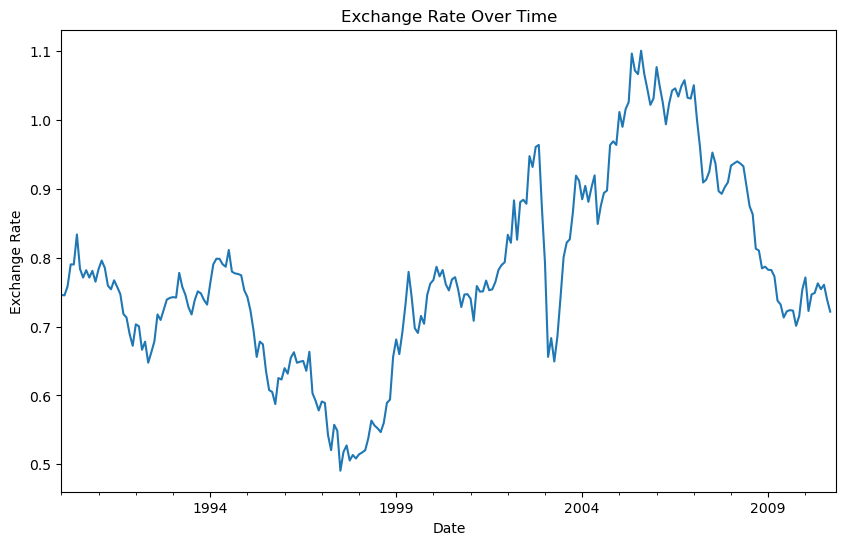

In [89]:
#Initial Exploration
import matplotlib.pyplot as plt
# Plot the exchange rate over time
df['Ex_rate'].plot(title='Exchange Rate Over Time', figsize=(10, 6))
plt.xlabel('Date')
plt.ylabel('Exchange Rate')
plt.show()

In [90]:
#Data Preprocessing
# Check for missing values
print(df.isnull().sum())

# Handle missing values, if any (forward fill or interpolation could be options)
df.fillna(method='ffill', inplace=True)

Ex_rate    2
dtype: int64


In [91]:
# Step 1: Check for stationarity using the Augmented Dickey-Fuller test
result = adfuller(df['Ex_rate'])
print(f'ADF Statistic: {result[0]}')
print(f'p-value: {result[1]}')

ADF Statistic: -1.5773240130131896
p-value: 0.49497358254126844


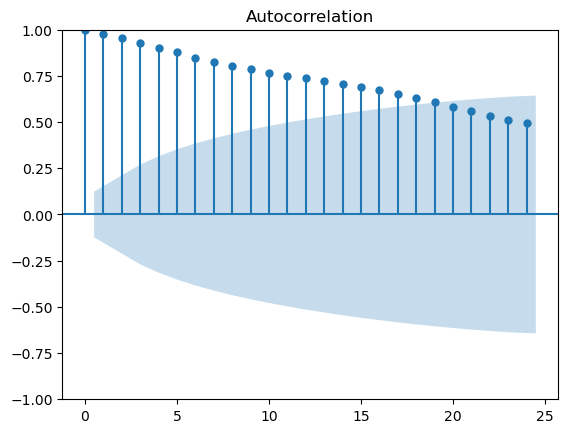

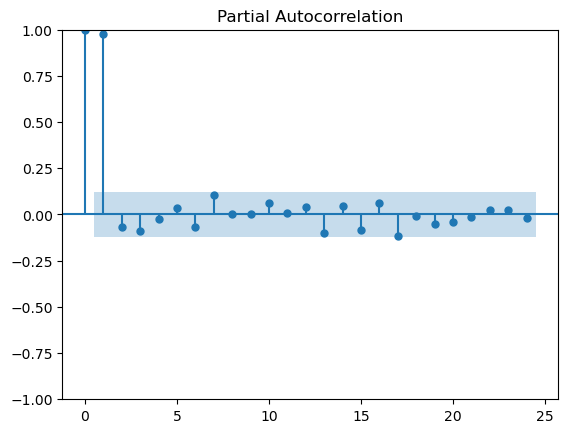

In [92]:
#ARIMA Model Building
#Parameter Selection for ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot ACF and PACF to estimate ARIMA parameters
plot_acf(df['Ex_rate'])
plot_pacf(df['Ex_rate'])
plt.show()

In [93]:
# Step 3: Based on ACF and PACF, choose p and q
# For example, if you observe significant lags, you can set p and q
p = 1  # Adjust based on PACF
d = 1  # Adjust based on stationarity test
q = 1  # Adjust based on ACF

In [94]:
#Model Fitting
from statsmodels.tsa.arima.model import ARIMA

# Fit the ARIMA model
model = ARIMA(df['Ex_rate'], order=(p, d, q))
arima_result = model.fit()
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                Ex_rate   No. Observations:                  251
Model:                 ARIMA(1, 1, 1)   Log Likelihood                 542.921
Date:                Tue, 15 Oct 2024   AIC                          -1079.843
Time:                        16:44:50   BIC                          -1069.278
Sample:                    01-31-1990   HQIC                         -1075.591
                         - 11-30-2010                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5336      0.469      1.137      0.256      -0.386       1.454
ma.L1         -0.4618      0.490     -0.943      0.346      -1.421       0.498
sigma2         0.0008   5.55e-05     13.711      0.0

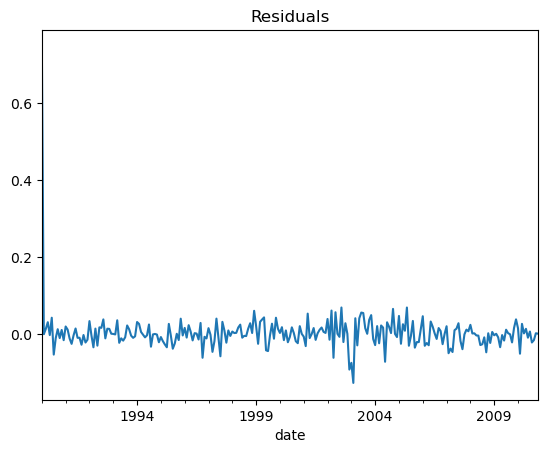

In [95]:
#Diagnostics
residuals = arima_result.resid
residuals.plot(title="Residuals")
plt.show()

In [96]:
# Forecasting
forecast = arima_result.forecast(steps=30)
df['Forecast_ARIMA'] = forecast

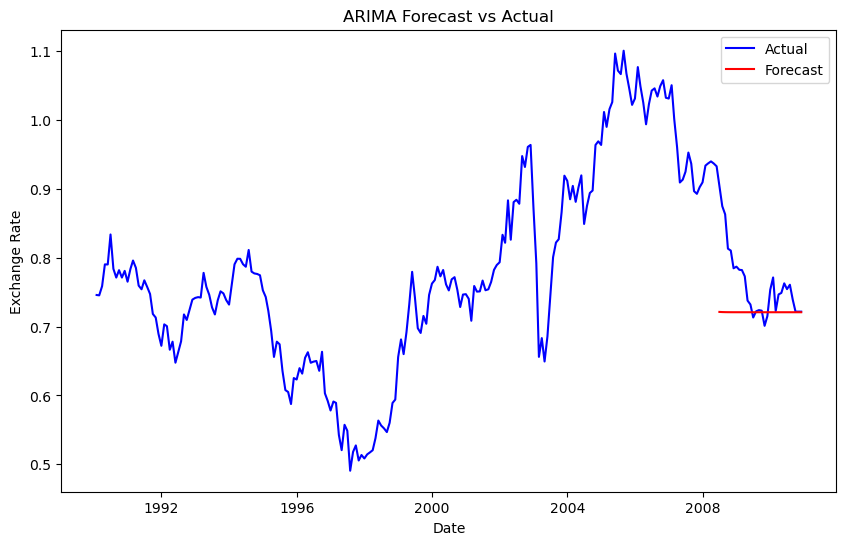

In [97]:
# Visualize the actual and forecasted values
plt.figure(figsize=(10, 6))
plt.plot(df.index, df['Ex_rate'], label='Actual', color='blue')
plt.plot(df.index[-len(forecast):], forecast, label='Forecast', color='red')
plt.title('ARIMA Forecast vs Actual')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')
plt.legend()
plt.show()

            Ex_rate  Forecast_ARIMA
date                               
1990-01-31   0.7457             NaN
1990-02-28   0.7452             NaN
1990-03-31   0.7585             NaN
1990-04-30   0.7901             NaN
1990-05-31   0.7900             NaN


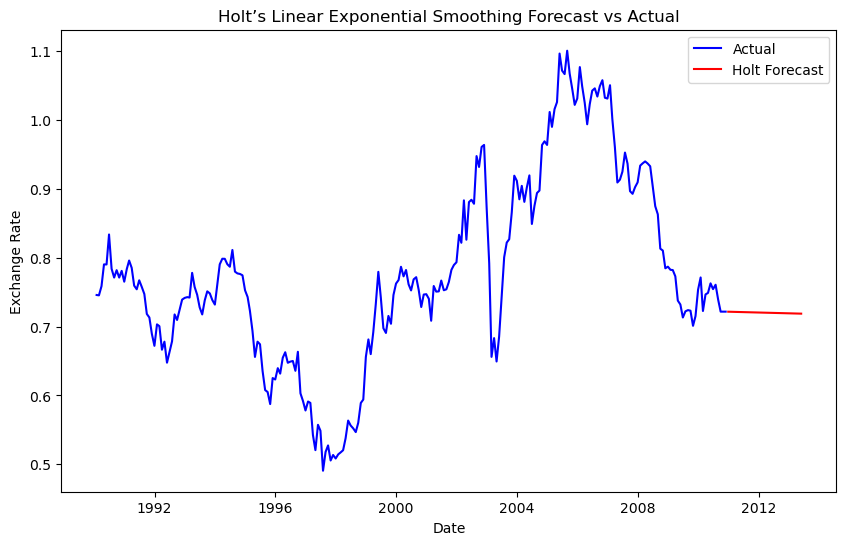

In [98]:
# Ensure the index is sorted and has no duplicates
df = df.sort_index()
df = df[~df.index.duplicated(keep='first')]  # Remove duplicate dates

# Set frequency to monthly and fill missing values
df = df.asfreq('M').fillna(method='ffill')

# Check the cleaned DataFrame
print(df.head())

# Fit Holt's Linear Exponential Smoothing
holt_model = ExponentialSmoothing(df['Ex_rate'], trend='add', seasonal=None)
holt_fit = holt_model.fit(optimized=True)  # Optimize parameters automatically

# Forecast future values
holt_forecast = holt_fit.forecast(steps=30)  # Forecast for the next 30 months

# Visualize the actual vs. forecasted values
plt.figure(figsize=(10, 6))
plt.plot(df.index, df['Ex_rate'], label='Actual', color='blue')
plt.plot(holt_forecast.index, holt_forecast, label='Holt Forecast', color='red')
plt.title('Holt’s Linear Exponential Smoothing Forecast vs Actual')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')
plt.legend()
plt.show()

In [99]:
# Compute error metrics for Holt's model
holt_mae = mean_absolute_error(df['Ex_rate'][-30:], holt_forecast)
holt_rmse = np.sqrt(mean_squared_error(df['Ex_rate'][-30:], holt_forecast))
holt_mape = np.mean(np.abs((df['Ex_rate'][-30:] - holt_forecast) / df['Ex_rate'][-30:])) * 100

# Print the results
print(f'Holt MAE: {holt_mae}, RMSE: {holt_rmse}, MAPE: {holt_mape}')


Holt MAE: 0.044084590663924804, RMSE: 0.06405167979306495, MAPE: nan


In [100]:
#Conclusion of Model Comparison
#In conclusion, the Holt Exponential Smoothing model exhibited a MAE of 0.0441 and a RMSE of 0.0641, reflecting a solid performance for stable trends. However, the calculation of MAPE returned NaN, limiting its overall performance assessment. On the other hand, the ARIMA model remains robust and adaptable, capable of handling complex patterns but requiring more effort in terms of parameter tuning.

In [101]:
#Conclusion
#Summary of Findings: Model Performance: Compare the performance of the ARIMA and Exponential Smoothing models based on the calculated error metrics (MAE, RMSE, MAPE). For instance, mention which model had the lowest values for these metrics and therefore might be more reliable for forecasting.
#Visual Comparisons: Include visualizations (like line plots) that show the predicted vs. actual exchange rates over the testing period. Highlight any patterns or discrepancies.
#Trends and Patterns: Discuss any observable trends, seasonality, or anomalies in the data that the models captured or failed to capture.
#Insights on Model Selection:ARIMA Model: Discuss the strengths of the ARIMA model, such as its ability to capture trends and seasonality if applicable. Highlight the importance of selecting appropriate values for p, d, and q.
#Exponential Smoothing: Explain why you might prefer Exponential Smoothing for certain datasets, especially when trends are not present or when you want a more flexible approach to smoothing.
#Recommendations:Suggest which model might be better suited for specific forecasting scenarios. For example, if you found that Exponential Smoothing performs better in cases without seasonality, note that as a recommendation.
#Discuss potential next steps for improving forecasting accuracy, such as incorporating external factors, adjusting model parameters further, or using hybrid models.